# Semantic Course Finder

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sumaiya-sultan-0008/LLM-Assigment/blob/education-dataset/semantic_retrieval.ipynb)

**Part A: Mini Project, Question 1 (Creative Semantic Retrieval)**
**Student:** _&lt;name / ID&gt;_

A student describes what they want to learn in their own words, for example *"teach a computer to learn from examples"* or *"I want to become a doctor"*, and the system suggests the 5 best-matching courses from a catalogue of 137 courses across 14 subjects.

**How it works:**

1. **Embed**: turn every course description and the student's request into a vector (a list of numbers) with a pretrained model.
2. **Compare**: measure how close the request is to each course with cosine similarity.
3. **Rank**: sort the courses from most to least similar.
4. **Return** the top 5.

**What we test:** three ways of making vectors (keyword-based TF-IDF, the small MiniLM model and the large GTE-large model) on 15 requests. Each request targets a different challenge. The catalogue also contains **decoys**: courses that share a word with a request but mean something else. For example, *"learn Python"* could pull in a biology course about pythons (the snakes), and *"what goes on inside cells"* could pull in a spreadsheet course, because spreadsheets have cells too.

**Key findings:**

* **GTE-large** puts a correct course first for **11 of the 14** scored requests and gets **P@5 = 0.67** on average. For comparison: MiniLM 0.60, TF-IDF 0.24, random 0.05.
* It is **perfect (5 of 5 correct)** on *"understand why people buy things"*, *"become more confident speaking in front of an audience"*, *"protect computers from viruses and hackers"*, *"study the stars and planets"* and *"learn Python"*. Words with two meanings (virus, stars, Python) cause no trouble when the rest of the request makes the meaning clear.
* It **fails** on the idiom *"a subject that isn't rocket science"*: 0 of 5 correct for every model, with the actual rocket science course ranked first. It also fails on the negation *"a science course with no maths"* (2 of 5), where maths-heavy courses come first. The request in Arabic gets 1 of 5.
* The word **"no" barely changes a vector**: *"a science course with maths"* and *"… with no maths"* have a similarity of 0.91–0.95.
* **Rewording helps**: saying *"an easy course for complete beginners"* instead of the idiom raises GTE-large from 0 to 4 of 5 correct.

## 0. Resources used

| Resource | What it is | Used for |
|---|---|---|
| `data/courses.json` | **Self-created dataset**: 137 short, made-up course descriptions in 14 subjects (computer science, maths, physics, chemistry, biology, geography, history, business, psychology, languages, arts, health, engineering, communication), each with a level (beginner / intermediate / advanced) | The catalogue we search |
| `data/queries.json` | **Self-created**: 15 student requests, each with the list of courses that truly match it and a list of decoys, written **before** running any model | Evaluation |
| [`thenlper/gte-large`](https://huggingface.co/thenlper/gte-large) | Pretrained sentence-embedding model, 335M parameters, 1024 numbers per text (MIT licence) | Large model |
| [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) | Pretrained sentence-embedding model, 22.7M parameters, 384 numbers per text (Apache-2.0) | Small model |
| TF-IDF (scikit-learn) | Word-count vectors with no understanding of meaning | Keyword-matching baseline |
| Libraries | `sentence-transformers`, PyTorch, scikit-learn, NumPy, pandas, matplotlib | |

No model is trained here. The pretrained models only turn text into vectors. The similarity, ranking and evaluation code is written out step by step below.

## 1. Setup

In **Google Colab**, run the cells from top to bottom (*Runtime → Run all*). A GPU is optional; on CPU the notebook takes a few minutes. The first run downloads about 0.8 GB of model weights.

In [1]:
# Colab already has most libraries; this installs sentence-transformers if it is missing.
%pip install -q sentence-transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from transformers.utils import logging

logging.set_verbosity_error()      # hide model-loading messages to keep the output tidy
logging.disable_progress_bar()
pd.set_option("display.max_colwidth", None)
BLUE, GREY = "#2a78d6", "#b0aea8"   # chart colours

## 2. The dataset: a course catalogue

Each course has a title, a subject, a level and a one-sentence description. The text we embed for each course is:

`"<Title> (<Subject>, <level> level): <Description>"`

In [3]:
# Download the data files from the project's GitHub repository (skipped if they are already here).
DATA_URL = "https://raw.githubusercontent.com/sumaiya-sultan-0008/LLM-Assigment/education-dataset/data/"
os.makedirs("data", exist_ok=True)
for file_name in ["courses.json", "queries.json"]:
    if not os.path.exists("data/" + file_name):
        urllib.request.urlretrieve(DATA_URL + file_name, "data/" + file_name)

with open("data/courses.json", encoding="utf-8") as f:
    courses = pd.DataFrame(json.load(f)).set_index("id")
with open("data/queries.json", encoding="utf-8") as f:
    queries = json.load(f)

# The text that gets embedded for each course
courses["text"] = (courses["title"] + " (" + courses["subject"] + ", " + courses["level"] + " level): "
                   + courses["description"])

print(len(courses), "courses and", len(queries), "queries\n")
print("Example:", courses.loc[1, "text"], "\n")
pd.crosstab(courses["subject"], courses["level"], margins=True, margins_name="total")

137 courses and 15 queries

Example: Introduction to Programming with Python (Computer Science, beginner level): Write your first programs in Python: variables, loops, functions and simple quizzes. No experience needed. 



level,advanced,beginner,intermediate,total
subject,,,,
Arts & Media,0,8,3,11
Biology,2,5,5,12
Business & Economics,2,9,3,14
Chemistry,2,3,3,8
Communication,0,3,1,4
Computer Science,5,10,7,22
Engineering,1,2,1,4
Geography,0,6,3,9
Health,0,3,3,6


### The test requests

For each request, `queries.json` lists the courses that match the **intended meaning** and the **decoys** (courses that share words with the request but mean something else). Q13 (`"bank"`) is deliberately ambiguous, so it is discussed but not scored.

In [4]:
pd.DataFrame([{
    "id": q["qid"],
    "what it tests": q["tests"],
    "request": q["query"],
    "intended meaning": q["meaning"],
    "matching courses": len(q["relevant"]),
    "decoys": len(q["decoys"]),
} for q in queries]).set_index("id")

,what it tests,request,intended meaning,matching courses,decoys
id,,,,,
Q1,"An easy, literal request",an introduction to computer programming,a beginner-friendly course that teaches coding,6,4
Q2,"Same idea, completely different words",teach a computer to learn from examples,machine learning / artificial intelligence,5,3
Q3,A word with two meanings (programming language vs snake),learn Python,courses on the Python programming language,5,1
Q4,"A word with many meanings (living cells vs spreadsheet, battery and prison cells)",what goes on inside cells,biology of living cells,5,4
Q5,Negation: the query says what it does NOT want,a science course with no maths,a descriptive science course that does not rely on calculations,11,4
Q6,An idiom: 'not rocket science' means 'easy',a subject that isn't rocket science,"an easy, beginner-friendly course",10,2
Q7,"A goal, not a topic ('doctor' also means PhD / Doctor Who)",I want to become a doctor,courses useful for studying medicine,11,2
Q8,Paraphrase of an everyday question,understand why people buy things,"marketing, consumer behaviour, behavioural economics",5,1
Q9,A personal skill ('speaking' also appears in language courses),become more confident speaking in front of an audience,public speaking and performance,5,1


## 3. Step 1: Turn text into vectors (embeddings)

We compare three ways of turning text into vectors:

| Name | How it works |
|---|---|
| **TF-IDF** | One number per vocabulary word, based on how often the word appears. Two texts only look similar if they share the **exact same words**. |
| **MiniLM** (small), **GTE-large** (large) | Neural models trained on millions of sentence pairs so that texts with **similar meaning** get similar vectors, even when they use different words. |

`model.encode(texts)` does the work for the two neural models. It splits each text into tokens, runs them through the transformer to get one vector per token, and then **averages** those vectors into a single vector for the whole text.

In [5]:
# Two pretrained sentence-embedding models (downloaded from Hugging Face on first use)
neural_models = {
    "MiniLM": SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2"),   # small and fast
    "GTE-large": SentenceTransformer("thenlper/gte-large"),                  # large and more accurate
}
for model in neural_models.values():
    model.float()   # use full 32-bit precision, so the results are the same on every computer

# Keyword baseline: TF-IDF, learned from the words in our catalogue
tfidf = TfidfVectorizer(stop_words="english", sublinear_tf=True).fit(courses["text"])


def embed(texts, model_name):
    """Turn a list of texts into a matrix of vectors (one row per text)."""
    if model_name == "TF-IDF":
        return tfidf.transform(texts).toarray()
    return neural_models[model_name].encode(texts)


MODELS = ["TF-IDF", "MiniLM", "GTE-large"]

# Embed the whole catalogue once for each model
course_vectors = {name: embed(list(courses["text"]), name) for name in MODELS}
for name in MODELS:
    print(f"{name:10} -> each course becomes a vector of {course_vectors[name].shape[1]} numbers")

TF-IDF     -> each course becomes a vector of 944 numbers
MiniLM     -> each course becomes a vector of 384 numbers
GTE-large  -> each course becomes a vector of 1024 numbers


## 4. Step 2: Cosine similarity

Cosine similarity measures the **angle** between two vectors: 1 means they point the same way (very similar), 0 means unrelated.

$$\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

If every vector is first scaled to length 1, the cosine is just the dot product. That lets us compare many vectors at once with a single matrix multiplication.

In [6]:
def normalize(vectors):
    """Scale every row to length 1."""
    lengths = np.linalg.norm(vectors, axis=1, keepdims=True)
    return vectors / np.maximum(lengths, 1e-10)    # the max(...) avoids dividing by zero


def cosine_similarity(a, b):
    """Cosine similarity between every row of a and every row of b."""
    return normalize(a) @ normalize(b).T


# Quick check against the formula written out by hand
a, b = np.array([[1.0, 2.0, 3.0]]), np.array([[2.0, 0.0, 1.0]])
by_hand = (a @ b.T) / (np.linalg.norm(a) * np.linalg.norm(b))
print("our function:", cosine_similarity(a, b)[0, 0].round(4), "| formula:", by_hand[0, 0].round(4))

our function: 0.5976 | formula: 0.5976


## 5. Steps 3 and 4: Rank the courses and return the top 5

In [7]:
def rank_courses(request, model_name):
    """All course ids sorted from most to least similar to the request, with their scores."""
    request_vector = embed([request], model_name)
    scores = cosine_similarity(request_vector, course_vectors[model_name])[0]
    order = np.argsort(-scores, kind="stable")    # highest score first (ties keep catalogue order)
    return courses.index[order], scores[order]


def search(request, model_name="GTE-large", k=5):
    """The top-k courses for a request, as a small table."""
    ids, scores = rank_courses(request, model_name)
    top = courses.loc[ids[:k], ["title", "subject", "level"]]
    top["score"] = scores[:k].round(3)
    return top


search("teach a computer to learn from examples")

,title,subject,level,score
id,,,,
11,Machine Learning Fundamentals,Computer Science,intermediate,0.852
12,Deep Learning,Computer Science,advanced,0.825
14,Artificial Intelligence: An Overview,Computer Science,beginner,0.822
22,Touch Typing,Computer Science,beginner,0.816
16,Ethical Hacking,Computer Science,advanced,0.813


## 6. Results for every request, with a manual relevance check

Each table shows the top 5 from each model. Every result is marked using the labels written before the experiment:

* **✓** matches the intended meaning
* **✗ DECOY** shares a word or topic with the request, but has the wrong meaning
* **✗** not relevant

Scores can only be compared *within* one model. GTE-large gives almost everything a score between 0.7 and 0.9, while MiniLM uses a much wider range.

In [8]:
def judge(query, title):
    """Manual relevance mark for one retrieved course, from the labels in queries.json."""
    if not query["relevant"]:
        return ""                                  # Q13 has no labels
    if title in query["relevant"]:
        return "✓"
    if title in query["decoys"]:
        return "✗ DECOY"
    return "✗"


def show_results(query):
    print(f"\n{query['qid']} ({query['tests']}):  \"{query['query']}\"")
    print(f"Intended meaning: {query['meaning']}")
    table = {}
    for name in ["GTE-large", "MiniLM", "TF-IDF"]:
        ids, scores = rank_courses(query["query"], name)
        titles = courses.loc[ids[:5], "title"]
        table[name] = [f"{judge(query, t)}  {t} ({s:.2f})" for t, s in zip(titles, scores[:5])]
    display(pd.DataFrame(table, index=[1, 2, 3, 4, 5]))


for q in queries:
    show_results(q)


Q1 (An easy, literal request):  "an introduction to computer programming"
Intended meaning: a beginner-friendly course that teaches coding


,GTE-large,MiniLM,TF-IDF
1,✓ Introduction to Programming with Python (0.86),✓ Introduction to Programming with Python (0.61),✓ Introduction to Programming with Python (0.39)
2,✓ Java Programming (0.85),✓ Java Programming (0.56),✓ Java Programming (0.37)
3,✗ Data Structures and Algorithms (0.85),✗ Introduction to Robotics (0.49),✗ Introduction to Robotics (0.17)
4,✗ Natural Language Processing (0.83),✗ Data Structures and Algorithms (0.45),✗ DECOY Introduction to Economics (0.16)
5,✗ Artificial Intelligence: An Overview (0.83),✗ Databases and SQL (0.43),✗ DECOY Introduction to Psychology (0.15)



Q2 (Same idea, completely different words):  "teach a computer to learn from examples"
Intended meaning: machine learning / artificial intelligence


,GTE-large,MiniLM,TF-IDF
1,✓ Machine Learning Fundamentals (0.85),✗ Introduction to Programming with Python (0.42),✗ Ethical Hacking (0.25)
2,✓ Deep Learning (0.83),✗ Touch Typing (0.41),✗ Children's Literature (0.21)
3,✓ Artificial Intelligence: An Overview (0.82),✓ Deep Learning (0.39),✗ Touch Typing (0.20)
4,✗ Touch Typing (0.82),✓ Natural Language Processing (0.39),✗ Python for Beginners: Make Games (0.16)
5,✗ Ethical Hacking (0.81),✗ Ethical Hacking (0.38),✗ Learn to Play the Guitar (0.15)



Q3 (A word with two meanings (programming language vs snake)):  "learn Python"
Intended meaning: courses on the Python programming language


,GTE-large,MiniLM,TF-IDF
1,✓ Python for Beginners: Make Games (0.90),✓ Introduction to Programming with Python (0.74),✓ Python for Beginners: Make Games (0.38)
2,✓ Introduction to Programming with Python (0.89),✓ Python for Beginners: Make Games (0.68),✓ Introduction to Programming with Python (0.27)
3,✓ Automate Boring Tasks with Python (0.87),✓ Advanced Python: Speed and Performance (0.54),✓ Data Science with Python (0.27)
4,✓ Data Science with Python (0.87),✓ Automate Boring Tasks with Python (0.48),✓ Automate Boring Tasks with Python (0.26)
5,✓ Advanced Python: Speed and Performance (0.85),✓ Data Science with Python (0.42),✓ Advanced Python: Speed and Performance (0.25)


... (20 outputs left out)


Q14 (Control query in English (compare with Q15)):  "learning a foreign language"
Intended meaning: language courses


,GTE-large,MiniLM,TF-IDF
1,✓ French Language and Culture (0.85),✓ Conversational Spanish for Beginners (0.51),✗ Natural Language Processing (0.28)
2,✓ Conversational Spanish for Beginners (0.84),✓ Arabic for Beginners (0.51),✗ Memory and Learning (0.20)
3,✓ Arabic for Beginners (0.84),✓ French Language and Culture (0.50),✗ Child Development (0.20)
4,✓ Mandarin Chinese I (0.83),✓ Mandarin Chinese I (0.46),✗ Deep Learning (0.19)
5,✗ Natural Language Processing (0.82),✗ Natural Language Processing (0.39),✗ Machine Learning Fundamentals (0.18)



Q15 (The same query as Q14, written in Arabic):  "تعلم لغة أجنبية"
Intended meaning: same as Q14: language courses


,GTE-large,MiniLM,TF-IDF
1,✓ Arabic for Beginners (0.81),✓ Arabic for Beginners (0.37),✗ Introduction to Programming with Python (0.00)
2,✗ The Islamic Golden Age (0.80),✗ The Islamic Golden Age (0.27),✗ Python for Beginners: Make Games (0.00)
3,✗ Geography of the Middle East (0.79),✗ Ancient Egypt (0.24),✗ Automate Boring Tasks with Python (0.00)
4,✗ Ancient Egypt (0.78),✗ Geography of the Middle East (0.20),✗ Advanced Python: Speed and Performance (0.00)
5,✗ Deep Learning (0.77),✗ Natural Language Processing (0.13),✗ Web Development Basics (0.00)


## 7. Evaluation

Three simple measures for each request:

* **Top-1 correct**: is the #1 suggestion a matching course? (1 = yes, 0 = no)
* **P@5 (precision at 5)**: what fraction of the top 5 are matching courses? (every scored request has at least 5, so 1.0 is possible)
* **Decoys@5**: how many decoys got into the top 5? This measures *"related words, wrong meaning"*.

A **random** ranking (average of 200 shuffles) shows the chance level.

In [9]:
def evaluate(query, ranked_ids):
    """Top-1 correct, P@5 and Decoys@5 for one ranked list of course ids."""
    top5 = list(courses.loc[ranked_ids[:5], "title"])
    return {
        "Top-1 correct": int(top5[0] in query["relevant"]),
        "P@5": sum(t in query["relevant"] for t in top5) / 5,
        "Decoys@5": sum(t in query["decoys"] for t in top5),
    }


scored_queries = [q for q in queries if q["relevant"]]   # all except Q13 "bank"
rng = np.random.default_rng(0)
rows = []
for q in scored_queries:
    for name in MODELS:
        ids, _ = rank_courses(q["query"], name)
        rows.append({"model": name, "qid": q["qid"], **evaluate(q, ids)})
    random_runs = [evaluate(q, rng.permutation(courses.index)) for _ in range(200)]
    rows.append({"model": "Random", "qid": q["qid"], **pd.DataFrame(random_runs).mean().to_dict()})
results = pd.DataFrame(rows)

summary = results.groupby("model").agg({"Top-1 correct": "mean", "P@5": "mean", "Decoys@5": "sum"})
summary = summary.loc[["Random"] + MODELS].rename(columns={"Decoys@5": "Decoys@5 (total)"})
summary.round(3)

,Top-1 correct,P@5,Decoys@5 (total)
model,,,
Random,0.043,0.047,1.07
TF-IDF,0.500,0.243,10.00
MiniLM,0.714,0.600,4.00
GTE-large,0.786,0.671,3.00


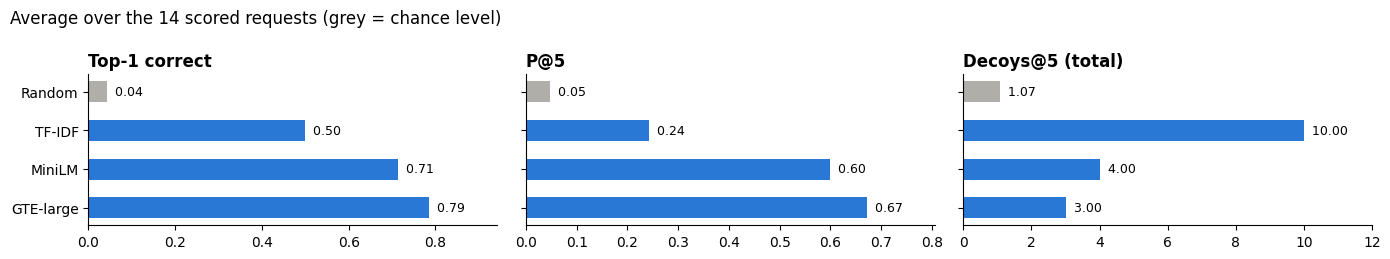

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 2.6), sharey=True)
for ax, column in zip(axes, summary.columns):
    colors = [GREY if name == "Random" else BLUE for name in summary.index]
    ax.barh(summary.index, summary[column], color=colors, height=0.55)
    for y, value in enumerate(summary[column]):
        ax.text(value, y, f"  {value:.2f}", va="center", fontsize=9)
    ax.set_title(column, loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, summary[column].max() * 1.2)
axes[0].invert_yaxis()
fig.suptitle(f"Average over the {len(scored_queries)} scored requests (grey = chance level)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Results per request

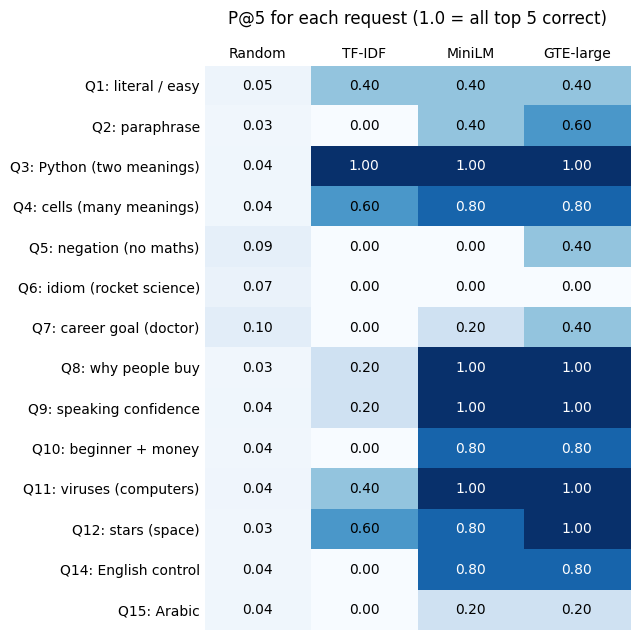

In [11]:
per_query = results.pivot(index="qid", columns="model", values="P@5")
per_query = per_query.loc[[q["qid"] for q in scored_queries], ["Random"] + MODELS]
labels = [f"{q['qid']}: {q['short']}" for q in scored_queries]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(per_query.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for row in range(per_query.shape[0]):
    for col in range(per_query.shape[1]):
        value = per_query.values[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", color="white" if value > 0.6 else "black")
ax.set_xticks(range(len(per_query.columns)), per_query.columns)
ax.set_yticks(range(len(labels)), labels)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("P@5 for each request (1.0 = all top 5 correct)", pad=30)
plt.tight_layout()
plt.show()

## 8. Deeper analysis: where do embeddings succeed and fail?

### 8.1 How does the model organise the catalogue?

For every course we find its **closest neighbour** (the course with the highest cosine similarity) and check whether the two share the same **subject** and the same **level**.

In [12]:
subjects = courses["subject"].values
levels = courses["level"].values


def closest_neighbour_check(vectors):
    similarity = cosine_similarity(vectors, vectors)
    np.fill_diagonal(similarity, -np.inf)          # a course cannot be its own neighbour
    closest = similarity.argmax(axis=1)
    return {"same subject": (subjects[closest] == subjects).mean(), "same level": (levels[closest] == levels).mean()}


def chance(labels):
    """Probability that two different, randomly picked courses share a label."""
    counts = pd.Series(labels).value_counts()
    return (counts * (counts - 1)).sum() / (len(labels) * (len(labels) - 1))


check = {"chance level": {"same subject": chance(subjects), "same level": chance(levels)}}
for name in MODELS:
    check[name] = closest_neighbour_check(course_vectors[name])
pd.DataFrame(check).T.round(3)

,same subject,same level
chance level,0.079,0.410
TF-IDF,0.796,0.526
MiniLM,0.715,0.569
GTE-large,0.752,0.679


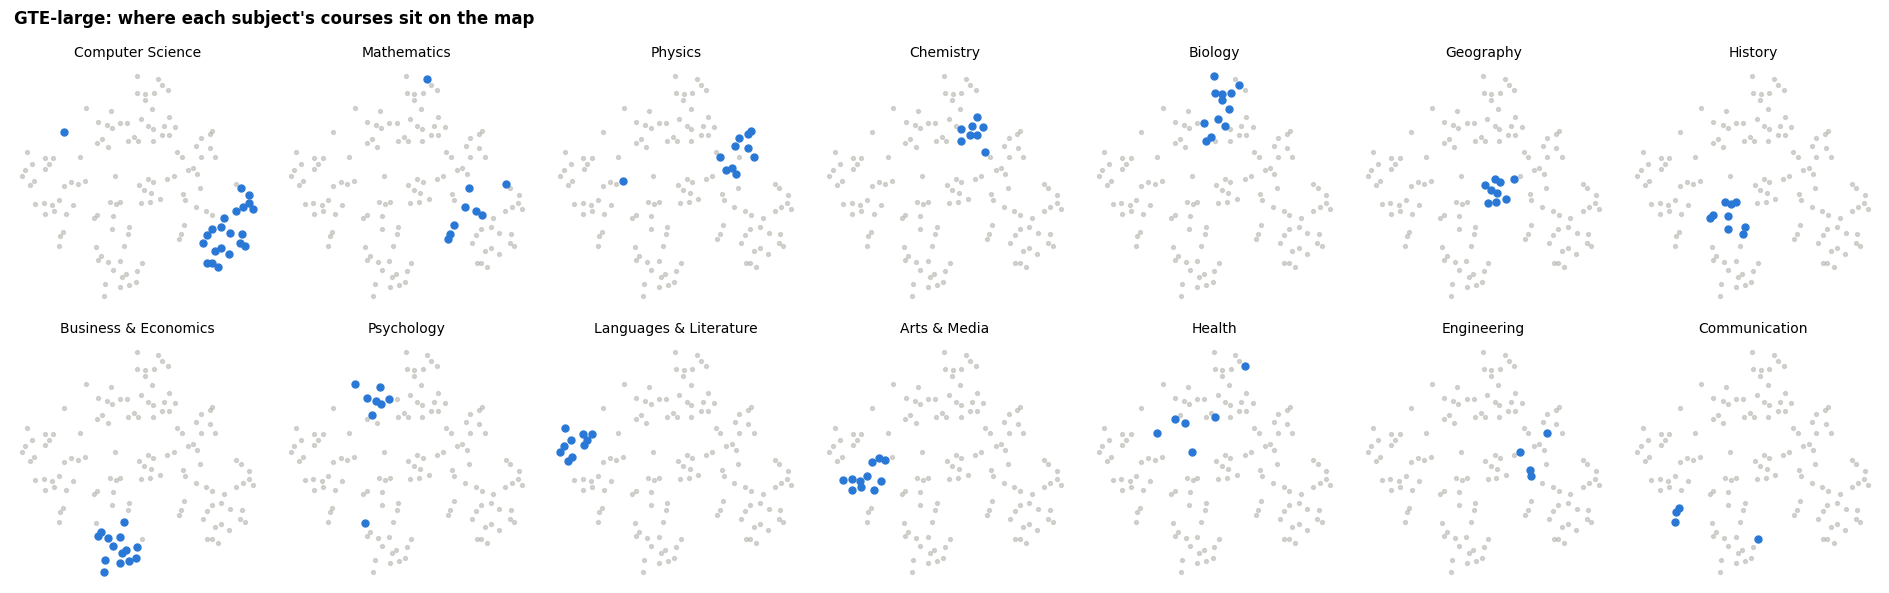

In [13]:
# A 2-D map of GTE-large's vectors (t-SNE). Each small panel highlights one subject in blue;
# a tight blue cluster means the model keeps that subject's courses together.
xy = TSNE(n_components=2, perplexity=15, init="pca", random_state=0).fit_transform(normalize(course_vectors["GTE-large"]))

groups = list(dict.fromkeys(subjects))
fig, axes = plt.subplots(2, 7, figsize=(19, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, group in zip(axes.flat, groups):
    in_group = subjects == group
    ax.scatter(xy[~in_group, 0], xy[~in_group, 1], s=8, color=GREY, alpha=0.5)
    ax.scatter(xy[in_group, 0], xy[in_group, 1], s=25, color=BLUE)
    ax.set_title(group, fontsize=10)
fig.suptitle("GTE-large: where each subject's courses sit on the map", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### 8.2 Negation, opposites and word order

Pairs of sentences that differ by one meaning-changing detail. A paraphrase pair (should score **high**) and an unrelated pair (should score **low**) are included for reference.

In [14]:
pairs = [
    ("paraphrase (should be HIGH)", "teach a computer to learn from examples", "a machine learning course"),
    ("unrelated (should be LOW)", "learn to play the guitar", "the chemistry of batteries"),
    ("negation", "a science course with maths", "a science course with no maths"),
    ("negation", "I like history", "I do not like history"),
    ("opposite", "a course for complete beginners", "a course for advanced experts"),
    ("opposite", "an easy subject", "a very difficult subject"),
    ("word order", "the teacher helps the student", "the student helps the teacher"),
]
rows = []
for relation, sentence_a, sentence_b in pairs:
    row = {"relation": relation, "sentence A": sentence_a, "sentence B": sentence_b}
    for name in MODELS:
        row[name] = cosine_similarity(embed([sentence_a], name), embed([sentence_b], name))[0, 0]
    rows.append(row)
pd.DataFrame(rows).round(3)

,relation,sentence A,sentence B,TF-IDF,MiniLM,GTE-large
0,paraphrase (should be HIGH),teach a computer to learn from examples,a machine learning course,0.0,0.491,0.855
1,unrelated (should be LOW),learn to play the guitar,the chemistry of batteries,0.0,0.050,0.699
2,negation,a science course with maths,a science course with no maths,1.0,0.908,0.954
3,negation,I like history,I do not like history,1.0,0.816,0.911
4,opposite,a course for complete beginners,a course for advanced experts,0.0,0.668,0.865
5,opposite,an easy subject,a very difficult subject,0.0,0.841,0.832
6,word order,the teacher helps the student,the student helps the teacher,0.0,0.988,0.993


**Does "no" change the search results?** We search with and without the word "no" and compare the two top-5 lists.

In [15]:
maths_heavy = ["Mathematical Biology", "Physics for Engineers", "Classical Mechanics", "Calculus I",
               "Statistics for Beginners", "Linear Algebra", "Rocket Science and Aerospace Engineering"]
for name in ["GTE-large", "MiniLM"]:
    with_no = search("a science course with no maths", name)
    without_no = search("a science course with maths", name)
    same = len(set(with_no.index) & set(without_no.index))
    heavy = sum(t in maths_heavy for t in with_no["title"])
    print(f"\n{name}: {same} of the 5 results are the same; {heavy} of the 'no maths' results are maths-heavy courses")
    display(pd.DataFrame({"a science course with maths": list(without_no["title"]),
                          "a science course with no maths": list(with_no["title"])}, index=[1, 2, 3, 4, 5]))


GTE-large: 2 of the 5 results are the same; 1 of the 'no maths' results are maths-heavy courses


,a science course with maths,a science course with no maths
1,Mathematical Biology,Physics for Engineers
2,Physics for Engineers,History of Science
3,Discrete Mathematics,Discrete Mathematics
4,Everyday Maths Refresher,Introduction to Biology
5,Calculus I,Introduction to Astronomy



MiniLM: 5 of the 5 results are the same; 3 of the 'no maths' results are maths-heavy courses


,a science course with maths,a science course with no maths
1,Physics for Engineers,Physics for Engineers
2,Discrete Mathematics,Discrete Mathematics
3,Everyday Maths Refresher,Everyday Maths Refresher
4,Calculus I,Linear Algebra
5,Linear Algebra,Calculus I


### 8.3 Two conditions at once (Q10: *"a beginner course about managing my own money"*)

Does the model respect both the **topic** (personal money) and the **level** (beginner)?

In [16]:
q10 = next(q for q in queries if q["qid"] == "Q10")
for name in MODELS:
    ids, _ = rank_courses(q10["query"], name)
    top5 = courses.loc[ids[:5]]
    print(f"{name:10} beginner-level: {(top5['level'] == 'beginner').sum()}/5 | correct: "
          f"{sum(t in q10['relevant'] for t in top5['title'])}/5 -> {', '.join(top5['title'])}")

TF-IDF     beginner-level: 3/5 | correct: 0/5 -> Entrepreneurship, History of Money and Banking, Behavioural Economics, Monetary Policy and Central Banks, Climate Change
MiniLM     beginner-level: 5/5 | correct: 4/5 -> Personal Finance, Investing for Beginners, History of Money and Banking, Accounting Basics, Budgeting for Students


GTE-large  beginner-level: 5/5 | correct: 4/5 -> Personal Finance, Investing for Beginners, Budgeting for Students, Accounting Basics, History of Money and Banking


### 8.4 A request in Arabic (Q15) compared with the same request in English (Q14)

Both models were trained on English text. The tokenizer output shows what they "see" when given Arabic.

In [17]:
arabic = next(q for q in queries if q["qid"] == "Q15")["query"]
print("Arabic request:", arabic, "(= 'learning a foreign language')")
print("What GTE-large sees:", neural_models["GTE-large"].tokenizer.tokenize(arabic), "\n")

display(results[results["qid"].isin(["Q14", "Q15"])].pivot(index="model", columns="qid", values="P@5").loc[MODELS])
for name in ["GTE-large", "MiniLM"]:
    print(f"{name:10} top 5 for the Arabic request: {', '.join(search(arabic, name)['title'])}")

Arabic request: تعلم لغة أجنبية (= 'learning a foreign language')
What GTE-large sees: ['ت', '##ع', '##ل', '##م', 'ل', '##غ', '##ة', 'ا', '##ج', '##ن', '##ب', '##ي', '##ة'] 



qid,Q14,Q15
model,,
TF-IDF,0.0,0.0
MiniLM,0.8,0.2
GTE-large,0.8,0.2


GTE-large  top 5 for the Arabic request: Arabic for Beginners, The Islamic Golden Age, Geography of the Middle East, Ancient Egypt, Deep Learning
MiniLM     top 5 for the Arabic request: Arabic for Beginners, The Islamic Golden Age, Ancient Egypt, Geography of the Middle East, Natural Language Processing


### 8.5 Does rewording the request help?

If a failure is caused by *how the request is worded* (negation, an idiom, another language), stating the same meaning plainly should fix it. Each rewrite was written once from the request's intended meaning, not tuned against the results. In a real system, an LLM could do this rewriting automatically.

In [18]:
rewrites = {
    "Q4": "the biology of living cells",
    "Q5": "a science course based on observation and description rather than calculation",
    "Q6": "an easy course for complete beginners",
    "Q7": "courses about medicine and the human body",
    "Q15": "learning a foreign language",   # English translation of the Arabic request
}
rows = []
for qid, new_text in rewrites.items():
    q = next(q for q in queries if q["qid"] == qid)
    for name in ["GTE-large", "MiniLM"]:
        before = evaluate(q, rank_courses(q["query"], name)[0])
        after = evaluate(q, rank_courses(new_text, name)[0])
        rows.append({"request": qid, "model": name, "rewritten as": new_text,
                     "P@5 before": before["P@5"], "P@5 after": after["P@5"],
                     "decoys before": before["Decoys@5"], "decoys after": after["Decoys@5"]})
pd.DataFrame(rows).set_index(["request", "model"])

rewritten as  \
request model                                                                                      
Q4      GTE-large                                                    the biology of living cells   
        MiniLM                                                       the biology of living cells   
Q5      GTE-large  a science course based on observation and description rather than calculation   
        MiniLM     a science course based on observation and description rather than calculation   
Q6      GTE-large                                          an easy course for complete beginners   
        MiniLM                                             an easy course for complete beginners   
Q7      GTE-large                                      courses about medicine and the human body   
        MiniLM                                         courses about medicine and the human body   
Q15     GTE-large                                                    learning a foreign language   
        MiniLM                                                       learning a foreign language   

                   P@5 before  P@5 after  decoys before  decoys after  
request model                                                          
Q4      GTE-large         0.8        0.6              0             0  
        MiniLM            0.8        0.6              0             0  
Q5      GTE-large         0.4        0.6              1             1  
        MiniLM            0.0        0.2              1             1  
Q6      GTE-large         0.0        0.8              2             0  
        MiniLM            0.0        0.4              2             0  
Q7      GTE-large         0.4        0.6              0             0  
        MiniLM            0.2        0.8              1             0  
Q15     GTE-large         0.2        0.8              0             0  
        MiniLM            0.2        0.8              0             0

## 9. Discussion

### 9.1 Manual check of GTE-large, request by request

| Request | Correct in top 5 | What happened |
|---|---|---|
| **Q1** an introduction to computer programming | 2 of 5 | *Introduction to Programming with Python* and *Java Programming* are ranked 1st and 2nd. The rest are computing courses that are not beginner coding (*Data Structures*, *NLP*, *AI*). TF-IDF pulled in *Introduction to Economics* and *Introduction to Psychology* only because they share the word "introduction". |
| **Q2** teach a computer to learn from examples | 3 of 5 | *Machine Learning*, *Deep Learning* and *AI* are ranked 1st to 3rd, although the request never says "machine learning". TF-IDF found none (no shared words). |
| **Q3** learn Python | 5 of 5 | Perfect for all three models. The snake course never appears. |
| **Q4** what goes on inside cells | 4 of 5 | Biology courses only. The spreadsheet, battery and prison "cells" decoys stay out. TF-IDF did retrieve the battery course (it mentions "fuel cells"). |
| **Q5** a science course with no maths | 2 of 5 | The #1 result is *Physics for Engineers* ("heavy use of mathematics"), and *Discrete Mathematics* is #3. MiniLM returned 5 maths courses. |
| **Q6** a subject that isn't rocket science | 0 of 5 | Every model ranked *Rocket Science and Aerospace Engineering* first, followed by space and physics courses. The idiom was read literally. |
| **Q7** I want to become a doctor | 2 of 5 | *Medical Ethics* and *First Aid* are found, but the top result is *History of Medicine*, and *Human Anatomy* and *Physiology* are missed. MiniLM and TF-IDF pulled in the *Doctor Who* course. |
| **Q8** understand why people buy things | 5 of 5 | Perfect: consumer behaviour, behavioural economics, marketing. |
| **Q9** speaking in front of an audience | 5 of 5 | Perfect. TF-IDF pulled in *Conversational Spanish* because it mentions "speaking". |
| **Q10** beginner course on managing my own money | 4 of 5 | All 5 are beginner-level. *History of Money and Banking* is the one miss. TF-IDF got 0 of 5 correct. |
| **Q11** protect computers from viruses and hackers | 5 of 5 | Perfect. TF-IDF pulled in *Virology* and *Microbiology* (biological viruses). |
| **Q12** study the stars and planets | 5 of 5 | Perfect. TF-IDF pulled in *Celebrity and Stardom in the Media*. |
| **Q13** "bank" | – | All models chose the **money** meaning. *Rivers and Flooding* ("river banks") appears only at #5 for GTE-large. |
| **Q14** learning a foreign language | 4 of 5 | Four language courses, plus *Natural Language Processing* (the computer meaning of "language"). |
| **Q15** the same request in Arabic | 1 of 5 | See 9.3. |

### 9.2 What types of queries produced good or poor results?

**Good:** requests that describe **what the student wants to learn in plain words**, even when those words are completely different from the course text:
- *why people buy things* → *Consumer Behaviour*
- *speaking in front of an audience* → *Public Speaking*, *Debating*, *Stand-up Comedy*
- *teach a computer to learn from examples* → *Machine Learning*

This is where embeddings beat keyword matching most clearly. On Q8, Q9 and Q10, GTE-large and MiniLM get 4–5 of 5 correct, while TF-IDF gets 0–1.

**Poor:** requests where the meaning is **hidden behind the literal words**:
- the idiom *"isn't rocket science"* (0 of 5)
- the negation *"no maths"* (2 of 5)
- the goal *"become a doctor"*, which needs reasoning about which subjects a future doctor should study (2 of 5)
- a request in another language (1 of 5)

**The bigger model helps**, but only moderately here: GTE-large scores 0.67 against MiniLM's 0.60. The largest gains are on the paraphrase (Q2), negation (Q5) and goal (Q7) requests. Neither model can handle the idiom.

### 9.3 Did the system retrieve items related to the topic but not the intended meaning?

Yes, but mostly for the keyword baseline. Over the 14 scored requests, decoys took **10 top-5 places for TF-IDF, 4 for MiniLM and 3 for GTE-large** (about 1 would be expected by chance).

* TF-IDF falls for almost every word trap: *viruses* → virology, *stars* → celebrity, *speaking* → Spanish, *cells* → batteries, *doctor* → Doctor Who.
* The neural models **avoid most of these traps**, because the rest of the request gives the context. "computers … hackers" tells them which kind of virus is meant.
* The neural models still fall for traps when the misleading words **are** the whole request: *rocket science* (Q6), *maths* (Q5), and *doctor* for MiniLM (Q7).

The **Arabic request** is a special case. The tokenizer splits it into single letters, so the model cannot understand it. Yet the results are not random: *Arabic for Beginners*, *The Islamic Golden Age*, *Geography of the Middle East* and *Ancient Egypt*. The models link Arabic script with Arab and Middle-Eastern topics, so they retrieve by **association** rather than meaning. It happens to get one correct answer (*Arabic for Beginners*), but for the wrong reason.

### 9.4 Which semantic relationships were captured well, and which poorly?

**Captured well**
* **Same idea, different words**: *learn from examples* ↔ *machine learning*; *why people buy* ↔ *consumer behaviour*; *speaking to an audience* ↔ *public speaking*.
* **Words with several meanings, when there is context**: Python, cells, viruses and stars were all resolved correctly by the neural models.
* **Subject structure**: an item's closest neighbour is in the same subject 75% of the time for GTE-large (chance: 8%), and the t-SNE map shows a separate cluster for each subject.
* **Level, partly**: for Q10, all 5 results were beginner courses, and the closest neighbour shares the level 68% of the time (chance: 41%).

**Captured poorly**
* **Negation**: *"with maths"* vs *"with no maths"* scores 0.91 (MiniLM) and 0.95 (GTE-large). MiniLM returns the **same 5 courses** for both searches.
* **Opposites**: *"an easy subject"* vs *"a very difficult subject"* scores 0.83–0.84, and *beginners* vs *advanced experts* scores 0.87 for GTE-large. That is higher than GTE-large gives many true matches.
* **Word order**: *"the teacher helps the student"* vs *"the student helps the teacher"* scores 0.99. Averaging the token vectors throws word order away.
* **Idioms and goals**: *"isn't rocket science"* is read as *rocket science*, and *"become a doctor"* is matched to courses *about* medicine rather than courses a future doctor needs.
* **Ambiguous single words**: *"bank"* with no context always means money. The model silently picks the most common meaning.

### 9.5 Limitations and failure cases

1. **Similar is not the same as relevant.** Cosine similarity measures shared topic. It ignores "no", opposites and word order, which often decide what a student actually wants.
2. **Idioms, goals and implied needs need reasoning**, not just matching ideas.
3. **Scores have no fixed meaning.** GTE-large gives almost every course a score between 0.7 and 0.9. Even the unreadable Arabic request's top result scores 0.81, not far below genuinely good matches (0.85–0.90). So there is no threshold for "nothing suitable": the system **always returns five courses**.
4. **English only.** Both models are trained on English. Arabic is broken into letters and handled by association, not meaning.
5. **Descriptions matter.** A course is only found if its short description mentions what the student cares about. *Human Anatomy* is useful for a future doctor, but its description never says "doctor" or "medicine", so it was missed.
6. **Evaluation limits.** The catalogue (137 courses) and the request set (14 scored) are small. One person wrote the courses, the requests and the labels, and whether a course "matches" can be a matter of opinion. The comparisons between models and request types are the reliable findings, not the exact numbers.

### 9.6 What would help, based on the experiments

* **Rewrite the request in plain words before searching** (for example, with an LLM). In Section 8.5, rewording the idiom raised GTE-large from 0 to 4 of 5 correct, and translating the Arabic request raised it from 1 to 4. Rewording is not a magic fix, though. The negation rewrite helped only a little (2 → 3), and the "cells" rewrite actually got slightly *worse* (4 → 3).
* **Use filters for hard conditions** such as level ("beginner") or "no maths", instead of hoping the embedding captures them.
* **Re-rank the top results with a cross-encoder**, a model that reads the request and the course *together* and can notice "no" and word order.
* **Use a multilingual model** for students who ask in Arabic or other languages.

### 9.7 Conclusion

Embeddings turn *"what should I study?"* into a nearest-neighbour search, and they work well whenever a student describes a topic in their own words. GTE-large gets 67% of its top-5 suggestions right, compared with 24% for keyword matching, and it is perfect on five requests where keyword matching was badly fooled by words with two meanings. But embeddings capture **what a sentence is about**, not **what it says about it**: "no maths", "isn't rocket science" and "the student helps the teacher" barely move the vector. They are a strong first step for a course finder, but reliable results need help from query rewriting, filters and re-ranking.

## 10. Try your own request

In [19]:
search("I want to design video games")

,title,subject,level,score
id,,,,
119,Graphic Design,Arts & Media,beginner,0.832
2,Python for Beginners: Make Games,Computer Science,beginner,0.825
7,Mobile App Development,Computer Science,intermediate,0.820
5,Web Development Basics,Computer Science,beginner,0.810
24,Linear Algebra,Mathematics,intermediate,0.802
